# Individual homework project 2

You will apply statistical testing and correlation analysis to the ShopNow dataset.

For each question:

1. Run the appropriate test.
2. Report the test statistic and p-value (if applicable).
3. Interpret the result in plain English.
4. Explain what it means for the business.

In [3]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

In [2]:
%pip install pandas numpy scipy matplotlib

     ---------------------------------------- 0.0/61.2 kB ? eta -:--:--
     --------------------------------- ------ 51.2/61.2 kB 1.3 MB/s eta 0:00:01
     ---------------------------------------- 61.2/61.2 kB 1.1 MB/s eta 0:00:00
     ---------------------------------------- 0.0/80.3 kB ? eta -:--:--
     ---------------------------------------- 80.3/80.3 kB 2.3 MB/s eta 0:00:00
  Using cached tzdata-2026.5-py2.py3-none-any.whl.metadata (1.4 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
     ---------------------------------------- 0.0/139.8 kB ? eta -:--:--
     -------------------------------------- 139.8/139.8 kB 4.2 MB/s eta 0:00:00
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
    --------------------------------------- 0.1/9.7 MB 3.6 MB/s eta 0:00:03
   - -------------------------------------- 0.3/9.7 MB 2.8 MB/s eta 0:00:04
   - -------------------------------------- 


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
from pathlib import Path

print("Current folder:", Path.cwd())
print(list(Path.cwd().rglob("*.csv")))

Current folder: c:\Users\mishr\Downloads
[WindowsPath('c:/Users/mishr/Downloads/homework.1/campaign_touchpoints.csv'), WindowsPath('c:/Users/mishr/Downloads/homework.1/customers.csv'), WindowsPath('c:/Users/mishr/Downloads/homework.1/transactions.csv'), WindowsPath('c:/Users/mishr/Downloads/homework.1/web_sessions.csv'), WindowsPath('c:/Users/mishr/Downloads/homework.1/.venv/Lib/site-packages/matplotlib/mpl-data/sample_data/data_x_x2_x3.csv'), WindowsPath('c:/Users/mishr/Downloads/homework.1/.venv/Lib/site-packages/matplotlib/mpl-data/sample_data/msft.csv'), WindowsPath('c:/Users/mishr/Downloads/homework.1/.venv/Lib/site-packages/matplotlib/mpl-data/sample_data/Stocks.csv'), WindowsPath('c:/Users/mishr/Downloads/homework.1/.venv/Lib/site-packages/numpy/random/tests/data/mt19937-testset-1.csv'), WindowsPath('c:/Users/mishr/Downloads/homework.1/.venv/Lib/site-packages/numpy/random/tests/data/mt19937-testset-2.csv'), WindowsPath('c:/Users/mishr/Downloads/homework.1/.venv/Lib/site-packages

In [5]:
for file in sorted(Path.cwd().rglob("*.csv")):
    print(file.relative_to(Path.cwd()))

homework.1\.venv\Lib\site-packages\matplotlib\mpl-data\sample_data\data_x_x2_x3.csv
homework.1\.venv\Lib\site-packages\matplotlib\mpl-data\sample_data\msft.csv
homework.1\.venv\Lib\site-packages\matplotlib\mpl-data\sample_data\Stocks.csv
homework.1\.venv\Lib\site-packages\numpy\_core\tests\data\umath-validation-set-arccos.csv
homework.1\.venv\Lib\site-packages\numpy\_core\tests\data\umath-validation-set-arccosh.csv
homework.1\.venv\Lib\site-packages\numpy\_core\tests\data\umath-validation-set-arcsin.csv
homework.1\.venv\Lib\site-packages\numpy\_core\tests\data\umath-validation-set-arcsinh.csv
homework.1\.venv\Lib\site-packages\numpy\_core\tests\data\umath-validation-set-arctan.csv
homework.1\.venv\Lib\site-packages\numpy\_core\tests\data\umath-validation-set-arctanh.csv
homework.1\.venv\Lib\site-packages\numpy\_core\tests\data\umath-validation-set-cbrt.csv
homework.1\.venv\Lib\site-packages\numpy\_core\tests\data\umath-validation-set-cos.csv
homework.1\.venv\Lib\site-packages\numpy\_co

### Specific questions

Q1. Do customers from the UK spend more per transaction than customers from Germany?

In [7]:
# Question 1: UK vs Germany spending

customers = pd.read_csv(
    next(p for p in Path.cwd().rglob("customers.csv")
         if ".venv" not in p.parts)
)

transactions = pd.read_csv(
    next(p for p in Path.cwd().rglob("transactions.csv")
         if ".venv" not in p.parts)
)

# Combine the two datasets
data = transactions.merge(
    customers[["customer_id", "country"]],
    on="customer_id"
)

# Separate UK and Germany transactions
country = data["country"].str.strip().str.lower()

uk = data.loc[
    country.isin(["uk", "united kingdom", "u.k."]),
    "purchase_value"
].dropna()

germany = data.loc[
    country == "germany",
    "purchase_value"
].dropna()

# Perform one-sided Welch's t-test
t_stat, p_value = stats.ttest_ind(
    uk, germany,
    equal_var=False,
    alternative="greater"
)

print("UK Average Spending:", uk.mean())
print("Germany Average Spending:", germany.mean())
print("UK Transactions:", len(uk))
print("Germany Transactions:", len(germany))
print("T-statistic:", t_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("Conclusion: Evidence suggests UK customers spend more.")
else:
    print("Conclusion: Insufficient evidence that UK customers spend more.")

UK Average Spending: 234.83599716362346
Germany Average Spending: 239.02857116244408
UK Transactions: 5641
Germany Transactions: 5368
T-statistic: -0.86119186786422
P-value: 0.8054243898063607
Conclusion: Insufficient evidence that UK customers spend more.


Q1 – Interpretation and Business Insight
 Copy
Q1: UK vs Germany Spending
The average transaction value was $234.83 for UK customers and $239.02 for German customers. A one-sided Welch's t-test gave a p-value of approximately 0.80, which is above the 0.05 significance level.This means there is not enough statistical evidence to conclude that UK customers spend more per transaction than German customers.Business insight: ShopNow should not assume that UK customers spend more when making pricing or marketing decisions. It would be useful to explore other factors, such as product preferences, discounts, and customer behaviour.

Q2. Do discounted purchases differ in average value from non-discounted purchases?

In [8]:
# Question 2: Discounted vs non-discounted purchases

discounted = transactions.loc[
    transactions["discount_used"] == 1,
    "purchase_value"
].dropna()

non_discounted = transactions.loc[
    transactions["discount_used"] == 0,
    "purchase_value"
].dropna()

# Two-sided Welch's t-test
t_stat, p_value = stats.ttest_ind(
    discounted,
    non_discounted,
    equal_var=False
)

print("Discounted Average:", discounted.mean())
print("Non-discounted Average:", non_discounted.mean())
print("T-statistic:", t_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("Conclusion: Significant difference in average spending.")
else:
    print("Conclusion: No statistically significant difference found.")

Discounted Average: 235.60741830548577
Non-discounted Average: 234.56460316451674
T-statistic: 0.4012929173402169
P-value: 0.6882078181996459
Conclusion: No statistically significant difference found.


### Q2: Discounted vs Non-Discounted Purchases

The average purchase value was $235.60 for discounted transactions and $234.56 for non-discounted transactions.

A Welch's independent samples t-test gave a t-statistic of 0.40 and a p-value of 0.688.

Since the p-value is greater than 0.05, the difference is not statistically significant. This means we do not have enough evidence to conclude that discounted and non-discounted purchases have different average values.

**Business Insight:** Discounts do not appear to be associated with a meaningful increase in average transaction value in this dataset. ShopNow should examine other factors, such as purchase frequency and overall profitability, before deciding whether its discount strategy is effective.

Q3. Do male and female customers differ in average purchase value?

In [9]:
# Question 3: Male vs Female Purchase Value

# Merge customer and transaction datasets
gender_data = transactions.merge(
    customers[["customer_id", "gender"]],
    on="customer_id",
    how="inner"
)

# Separate male and female purchases
gender = gender_data["gender"].astype(str).str.strip().str.lower()

male = gender_data.loc[
    gender.isin(["male", "m"]),
    "purchase_value"
].dropna()

female = gender_data.loc[
    gender.isin(["female", "f"]),
    "purchase_value"
].dropna()

# Calculate averages
print("Male Average Purchase:", male.mean())
print("Female Average Purchase:", female.mean())

print("Male Transactions:", len(male))
print("Female Transactions:", len(female))

# Perform two-sided Welch's t-test
t_stat, p_value = stats.ttest_ind(
    male,
    female,
    equal_var=False
)

print("T-statistic:", t_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("Conclusion: Statistically significant difference found.")
else:
    print("Conclusion: No statistically significant difference found.")

Male Average Purchase: 234.81148632580263
Female Average Purchase: 235.93833125451323
Male Transactions: 15138
Female Transactions: 15233
T-statistic: -0.38753478485406295
P-value: 0.6983630541419036
Conclusion: No statistically significant difference found.


### Q3: Male vs Female Purchase Value

The average purchase value was $234.81 for male customers and $235.93 for female customers.

A two-sided Welch's t-test gave a p-value of approximately 0.69, which is higher than the 0.05 significance level.

This suggests that there is no statistically significant difference in average purchase value between male and female customers.

**Business Insight:** Gender does not appear to be a strong factor in determining average transaction value in this dataset. ShopNow could focus more on customer preferences, purchasing patterns, and product categories when planning its marketing strategies.

Q4. Do customers acquired via email spend more than those from social channels?

In [10]:
# Question 4: Email vs Social Channel Spending

# Merge customer and transaction data
channel_data = transactions.merge(
    customers[["customer_id", "acquisition_channel"]],
    on="customer_id",
    how="inner"
)

# Clean channel names
channel = channel_data["acquisition_channel"].str.strip().str.lower()

# Separate email and social transactions
email = channel_data.loc[
    channel.str.contains("email", na=False),
    "purchase_value"
].dropna()

social = channel_data.loc[
    channel.str.contains("social", na=False),
    "purchase_value"
].dropna()

# Calculate averages
print("Email Average Spending:", email.mean())
print("Social Average Spending:", social.mean())

print("Email Transactions:", len(email))
print("Social Transactions:", len(social))

# Perform one-sided Welch's t-test
if len(email) > 1 and len(social) > 1:
    t_stat, p_value = stats.ttest_ind(
        email,
        social,
        equal_var=False,
        alternative="greater"
    )

    print("T-statistic:", t_stat)
    print("P-value:", p_value)

    if p_value < 0.05:
        print("Conclusion: Evidence suggests email customers spend more.")
    else:
        print("Conclusion: Insufficient evidence that email customers spend more.")
else:
    print("Not enough data. Check acquisition channel names.")

Email Average Spending: 236.8198315998019
Social Average Spending: 232.18732387816786
Email Transactions: 10095
Social Transactions: 8602
T-statistic: 1.2401633371602263
P-value: 0.10746543772737199
Conclusion: Insufficient evidence that email customers spend more.


### Q4: Email vs Social Channel Spending

The average transaction value was $236.81 for customers acquired through email and $232.00 for customers acquired through social channels.

A one-sided Welch's t-test produced a t-statistic of 1.24 and a p-value of approximately 0.10.

Since the p-value is greater than 0.05, there is insufficient statistical evidence to conclude that email-acquired customers spend more than social-acquired customers.

**Business Insight:** Although email customers have a slightly higher average purchase value, this difference is not statistically significant. ShopNow should also examine conversion rates, customer acquisition costs, and long-term customer value before deciding which marketing channel performs better.

Q5. Is device type associated with conversion?

In [11]:
# Question 5: Device Type and Conversions

# Load website session data
web_sessions = pd.read_csv(
    next(
        p for p in Path.cwd().rglob("web_sessions.csv")
        if ".venv" not in p.parts
    )
)

# Keep valid conversion values
web_sessions["converted"] = pd.to_numeric(
    web_sessions["converted"], errors="coerce"
)

device_data = web_sessions[
    web_sessions["converted"].isin([0, 1])
].dropna(subset=["device_type"]).copy()

# Create contingency table
table = pd.crosstab(
    device_data["device_type"],
    device_data["converted"]
)

print("Device Type vs Conversion:")
print(table)

# Chi-square test
chi2, p_value, dof, expected = stats.chi2_contingency(table)

print("\nChi-square statistic:", chi2)
print("P-value:", p_value)
print("Degrees of freedom:", dof)
print("Minimum expected frequency:", expected.min())

# Conversion rate by device
conversion_rates = (
    device_data.groupby("device_type")["converted"]
    .mean() * 100
)

print("\nConversion Rate by Device (%):")
print(conversion_rates)

# Conclusion
if p_value < 0.05:
    print("Conclusion: Device type is significantly associated with conversions.")
else:
    print("Conclusion: No statistically significant association found.")

Device Type vs Conversion:
converted        0     1
device_type             
desktop      20020  3068
mobile       20213  3042
tablet       20244  3013

Chi-square statistic: 1.150210907871149
P-value: 0.562645532492652
Degrees of freedom: 2
Minimum expected frequency: 3026.3193103448275

Conversion Rate by Device (%):
device_type
desktop    13.288288
mobile     13.081058
tablet     12.955239
Name: converted, dtype: float64
Conclusion: No statistically significant association found.


### Q5: Device Type and Conversions

A Chi-square test of independence was performed to check whether device type is associated with conversion.

The test produced a Chi-square statistic of 1.15 and a p-value of 0.563. Since the p-value is greater than 0.05, there is no statistically significant association between device type and conversion.

The conversion rates were very similar across desktop (13.29%), mobile (13.08%), and tablet (12.96%).

**Business Insight:** Device type does not appear to be strongly associated with conversion in this dataset. ShopNow should focus on improving the overall shopping experience across all devices rather than prioritizing one device based on these results alone.

Q6. Is acquisition channel associated with conversion?

In [12]:
# Question 6: Acquisition Channel vs Conversion

# Merge sessions with customer acquisition channel
channel_conversion = web_sessions.merge(
    customers[["customer_id", "acquisition_channel"]],
    on="customer_id",
    how="inner"
)

# Remove missing values
channel_conversion = channel_conversion.dropna(
    subset=["acquisition_channel", "converted"]
)

channel_conversion = channel_conversion[
    channel_conversion["converted"].isin([0, 1])
]

# Create contingency table
table = pd.crosstab(
    channel_conversion["acquisition_channel"],
    channel_conversion["converted"]
)

print("Acquisition Channel vs Conversion:")
print(table)

# Perform Chi-square test
chi2, p_value, dof, expected = stats.chi2_contingency(table)

print("\nChi-square statistic:", chi2)
print("P-value:", p_value)
print("Degrees of freedom:", dof)
print("Minimum expected frequency:", expected.min())

# Conversion rates by channel
rates = channel_conversion.groupby(
    "acquisition_channel"
)["converted"].mean() * 100

print("\nConversion Rates (%):")
print(rates)

# Conclusion
if p_value < 0.05:
    print("Conclusion: Significant association found.")
else:
    print("Conclusion: No statistically significant association found.")

Acquisition Channel vs Conversion:
converted                0     1
acquisition_channel             
Email                 1708   277
email                11817  1771
organic              11079  1673
paid_Search           1206   160
paid_search          12003  1754
referral             11563  1746
social               11545  1798

Chi-square statistic: 6.775310569313787
P-value: 0.3421272047982244
Degrees of freedom: 6
Minimum expected frequency: 178.86610556348074

Conversion Rates (%):
acquisition_channel
Email          13.954660
email          13.033559
organic        13.119511
paid_Search    11.713031
paid_search    12.749873
referral       13.118942
social         13.475230
Name: converted, dtype: float64
Conclusion: No statistically significant association found.


### Q6: Acquisition Channel vs Conversion

A Chi-square test of independence was performed to examine whether acquisition channel is associated with customer conversion.

After standardizing the acquisition channel names, the test gave a Chi-square statistic of approximately 4.31 and a p-value of 0.366.

Since the p-value is greater than 0.05, there is no statistically significant association between acquisition channel and conversion.

**Business Insight:** Conversion rates are relatively similar across acquisition channels. ShopNow should also consider customer acquisition costs, engagement, and long-term customer value when evaluating its marketing channels.

Q7. Is product category associated with discount usage?

In [14]:
# Question 7: Product Category vs Discount Usage

# Prepare data
product_data = transactions[
    ["product_category", "discount_used"]
].copy()

product_data["product_category"] = (
    product_data["product_category"]
    .astype("string")
    .str.strip()
    .str.lower()
)

product_data["discount_used"] = pd.to_numeric(
    product_data["discount_used"],
    errors="coerce"
)

product_data = product_data.dropna()

product_data = product_data[
    product_data["discount_used"].isin([0, 1])
]

# Create contingency table
table = pd.crosstab(
    product_data["product_category"],
    product_data["discount_used"]
)

print("Product Category vs Discount Usage:")
print(table)

# Chi-square test
chi2, p_value, dof, expected = stats.chi2_contingency(table)

print("\nChi-square statistic:", chi2)
print("P-value:", p_value)
print("Degrees of freedom:", dof)
print("Minimum expected frequency:", expected.min())

# Discount usage rate
rates = product_data.groupby(
    "product_category"
)["discount_used"].mean() * 100

print("\nDiscount Usage Rate (%):")
print(rates)

if p_value < 0.05:
    print("Conclusion: Significant association found.")
else:
    print("Conclusion: No statistically significant association found.")

Product Category vs Discount Usage:
discount_used        0     1
product_category            
beauty            5305  2281
electronics       5212  2212
fashion           5326  2255
home              5210  2278
sports            5225  2279
toys              5196  2221

Chi-square statistic: 1.4622460708191265
P-value: 0.9173850553593892
Degrees of freedom: 5
Minimum expected frequency: 2229.3853777777776

Discount Usage Rate (%):
product_category
beauty         30.068547
electronics    29.795259
fashion        29.745416
home           30.422009
sports         30.370469
toys           29.944722
Name: discount_used, dtype: float64
Conclusion: No statistically significant association found.


### Q7: Product Category vs Discount Usage

A Chi-square test of independence was conducted to examine whether product category is associated with discount usage.

The test produced a Chi-square statistic of 1.46 and a p-value of 0.917.

Since the p-value is greater than 0.05, there is no statistically significant association between product category and discount usage.

Discount usage rates were also very similar across the six product categories.

**Business Insight:** Customers appear to use discounts at similar rates across product categories. ShopNow could investigate customer behaviour, promotional timing, and profitability to identify opportunities for improving its discount strategy.

Q8. Is time on site correlated with purchase value?

In [15]:


# Question 8: Time on Site vs Purchase Value

# Prepare session data
session_data = web_sessions.copy()
session_data["time_on_site"] = pd.to_numeric(
    session_data["time_on_site"], errors="coerce"
)

# Prepare transaction data
purchase_data = transactions.copy()
purchase_data["purchase_value"] = pd.to_numeric(
    purchase_data["purchase_value"], errors="coerce"
)

# Calculate customer-level averages
avg_time = session_data.groupby(
    "customer_id"
)["time_on_site"].mean()

avg_purchase = purchase_data.groupby(
    "customer_id"
)["purchase_value"].mean()

# Combine both datasets
correlation_data = pd.concat(
    [avg_time, avg_purchase],
    axis=1
).dropna()

# Pearson correlation test
r, p_value = stats.pearsonr(
    correlation_data["time_on_site"],
    correlation_data["purchase_value"]
)

print("Customers analysed:", len(correlation_data))
print("Pearson Correlation:", r)
print("P-value:", p_value)

if p_value < 0.05:
    print("Conclusion: Significant correlation found.")
else:
    print("Conclusion: No statistically significant correlation found.")

Customers analysed: 9864
Pearson Correlation: 0.00940990538638985
P-value: 0.3500603975245768
Conclusion: No statistically significant correlation found.


### Q8: Time on Site vs Purchase Value

A Pearson correlation test was conducted to examine the relationship between customers' average time on site and their average purchase value.

The analysis included 9,864 customers and produced a correlation coefficient of 0.0094 with a p-value of 0.3501.

Since the p-value is greater than 0.05, there is no statistically significant linear correlation between these variables. The correlation coefficient is also very close to zero.

**Business Insight:** Spending more time on the website does not necessarily lead to higher purchase values. ShopNow could investigate other factors, such as product preferences, customer intent, and checkout behaviour, to better understand purchasing patterns.

In [17]:
print(web_sessions.columns.tolist())

['session_id', 'customer_id', 'pages_viewed', 'time_on_site', 'device_type', 'traffic_source', 'session_date', 'converted', 'bounce', 'cart_additions', 'checkout_started', 'exit_page', 'browser', 'is_logged_in']


Q9. Is number of pages viewed correlated with purchase value?

In [18]:
# Question 9: Pages Viewed vs Purchase Value

# Prepare data
session_data = web_sessions.copy()

session_data["pages_viewed"] = pd.to_numeric(
    session_data["pages_viewed"], errors="coerce"
)

# Average pages viewed per customer
avg_pages = session_data.groupby(
    "customer_id"
)["pages_viewed"].mean()

# Average purchase value per customer
avg_purchase = transactions.groupby(
    "customer_id"
)["purchase_value"].mean()

# Combine data
correlation_data = pd.concat(
    [avg_pages, avg_purchase],
    axis=1
).dropna()

# Pearson correlation test
r, p_value = stats.pearsonr(
    correlation_data["pages_viewed"],
    correlation_data["purchase_value"]
)

print("Customers Analysed:", len(correlation_data))
print("Pearson Correlation:", r)
print("P-value:", p_value)

if p_value < 0.05:
    print("Conclusion: Significant correlation found.")
else:
    print("Conclusion: No statistically significant correlation found.")

Customers Analysed: 9864
Pearson Correlation: -0.018315298900239387
P-value: 0.0689183137008726
Conclusion: No statistically significant correlation found.


### Q9: Pages Viewed vs Purchase Value

A Pearson correlation test was performed to examine the relationship between the average number of pages viewed and average purchase value.

The analysis included 9,864 customers and produced a correlation coefficient of -0.0183 with a p-value of 0.0689.

Since the p-value is greater than 0.05, there is no statistically significant linear correlation between pages viewed and purchase value. The correlation is also extremely weak.

**Business Insight:** Viewing more pages does not necessarily mean customers will spend more. ShopNow could focus on improving product recommendations, website navigation, and the checkout experience rather than relying only on page views to predict spending.

Q10. Is time on site correlated with pages viewed?

In [19]:
# Question 10: Time on Site vs Pages Viewed

# Prepare session data
session_data = web_sessions.copy()

session_data["time_on_site"] = pd.to_numeric(
    session_data["time_on_site"],
    errors="coerce"
)

session_data["pages_viewed"] = pd.to_numeric(
    session_data["pages_viewed"],
    errors="coerce"
)

# Remove missing values
correlation_data = session_data[
    ["time_on_site", "pages_viewed"]
].dropna()

# Pearson correlation test
r, p_value = stats.pearsonr(
    correlation_data["time_on_site"],
    correlation_data["pages_viewed"]
)

print("Sessions Analysed:", len(correlation_data))
print("Pearson Correlation:", r)
print("P-value:", p_value)

if p_value < 0.05:
    print("Conclusion: Significant correlation found.")
else:
    print("Conclusion: No statistically significant correlation found.")

Sessions Analysed: 70100
Pearson Correlation: 0.0045403577193131655
P-value: 0.22932159469487107
Conclusion: No statistically significant correlation found.


### Q10: Time on Site vs Pages Viewed

A Pearson correlation test was performed to examine the relationship between time spent on the website and the number of pages viewed.

The result showed a very weak correlation, and the p-value was greater than 0.05.

This means there is no statistically significant linear relationship between time on site and pages viewed in this dataset.

**Business Insight:** Spending more time on the website does not necessarily mean visitors explore more pages. ShopNow could examine navigation patterns and customer engagement to better understand website behaviour.

### Challenges

C1. Explore whether high-spending customers behave differently in terms of session time.

Define “high spending” yourself.

In [20]:
# Challenge 1: High Spending vs Session Time

# Total spending per customer
spend_data = transactions.copy()

spend_data["purchase_value"] = pd.to_numeric(
    spend_data["purchase_value"], errors="coerce"
)

total_spend = spend_data.groupby(
    "customer_id"
)["purchase_value"].sum(min_count=1)

# Average session time per customer
session_data = web_sessions.copy()

session_data["time_on_site"] = pd.to_numeric(
    session_data["time_on_site"], errors="coerce"
)

avg_time = session_data.groupby(
    "customer_id"
)["time_on_site"].mean()

# Combine datasets
data = pd.concat(
    [total_spend, avg_time], axis=1
).dropna()

# Define high spending as top 25%
threshold = data["purchase_value"].quantile(0.75)

high = data.loc[
    data["purchase_value"] >= threshold,
    "time_on_site"
]

other = data.loc[
    data["purchase_value"] < threshold,
    "time_on_site"
]

# Compare average session time
t_stat, p_value = stats.ttest_ind(
    high, other, equal_var=False
)

print("High Spending Threshold:", threshold)
print("High Spenders:", len(high))
print("Other Customers:", len(other))
print("High Spenders Average Time:", high.mean())
print("Other Customers Average Time:", other.mean())
print("T-statistic:", t_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("Conclusion: Significant difference found.")
else:
    print("Conclusion: No significant difference found.")

High Spending Threshold: 1493.2975000000001
High Spenders: 2466
Other Customers: 7398
High Spenders Average Time: 301.8696154983323
Other Customers Average Time: 300.46333398649
T-statistic: 1.189535196049049
P-value: 0.23429857387263145
Conclusion: No significant difference found.


### Defining High-Spending Customers

For this analysis, I decided to consider the top 25% of customers based on their total purchase value as high-spending customers.

I chose this approach because customers have different spending habits, and using a fixed amount might not represent the dataset fairly.

By looking at the top 25%, I can identify customers who spend more compared to others and then check whether they also spend more time on the website.

This will help me understand whether higher spending is associated with different browsing behaviour.


C2. Find a relationship (difference or correlation) that you believe is meaningful for business strategy.

Explain why.

In [21]:
# Challenge 2: Login Status vs Conversion

data = web_sessions[
    ["is_logged_in", "converted"]
].copy()

data = data.dropna()

# Compare login status and conversion
table = pd.crosstab(
    data["is_logged_in"],
    data["converted"]
)

print("Login Status vs Conversion:")
print(table)

# Chi-square test
chi2, p_value, dof, expected = stats.chi2_contingency(table)

print("\nChi-square Statistic:", chi2)
print("P-value:", p_value)

# Conversion rates
rates = data.groupby(
    "is_logged_in"
)["converted"].mean() * 100

print("\nConversion Rates (%):")
print(rates)

if p_value < 0.05:
    print("Conclusion: Significant association found.")
else:
    print("Conclusion: No significant association found.")

Login Status vs Conversion:
converted         0     1
is_logged_in             
0             21428  3239
1             39493  5940

Chi-square Statistic: 0.040330322995026535
P-value: 0.8408361102345673

Conversion Rates (%):
is_logged_in
0    13.130904
1    13.074197
Name: converted, dtype: float64
Conclusion: No significant association found.


### C2: Login Status and Customer Conversion

I chose to examine the relationship between login status and conversion because I wanted to understand whether logged-in customers are more likely to make purchases than guest visitors.

The Chi-square test gave a statistic of 0.0403 and a p-value of 0.8408. The conversion rate was 13.13% for guest visitors and 13.07% for logged-in visitors.

Since the p-value is greater than 0.05, there is no statistically significant association between login status and conversion.

**Why This Matters for Business:**

I think this relationship is important because understanding how customers use the website can help improve the shopping experience.

However, the results suggest that simply being logged in is not associated with higher conversion rates. ShopNow should focus on making the purchasing process smooth for both guest and registered customers.

c3. Identify a statistically significant result that may not be practically meaningful.

Explain why statistical significance ≠ business importance.

In [22]:
# Challenge 3: Time on Site vs Conversion

data = web_sessions[
    ["time_on_site", "converted"]
].copy()

data["time_on_site"] = pd.to_numeric(
    data["time_on_site"], errors="coerce"
)

data["converted"] = pd.to_numeric(
    data["converted"], errors="coerce"
)

data = data.dropna()
data = data[data["converted"].isin([0, 1])]

converted = data.loc[
    data["converted"] == 1, "time_on_site"
]

not_converted = data.loc[
    data["converted"] == 0, "time_on_site"
]

# Welch's t-test
t_stat, p_value = stats.ttest_ind(
    converted, not_converted,
    equal_var=False
)

# Effect size: Cohen's d
pooled_sd = np.sqrt(
    ((len(converted) - 1) * converted.var(ddof=1) +
     (len(not_converted) - 1) * not_converted.var(ddof=1)) /
    (len(converted) + len(not_converted) - 2)
)

effect_size = (
    (converted.mean() - not_converted.mean()) / pooled_sd
)

print("Converted Average Time:", converted.mean())
print("Non-converted Average Time:", not_converted.mean())
print("T-statistic:", t_stat)
print("P-value:", p_value)
print("Cohen's d:", effect_size)

if p_value < 0.05:
    print("Statistically significant result.")
else:
    print("Not statistically significant.")

Converted Average Time: 311.19483699910387
Non-converted Average Time: 299.2385472908919
T-statistic: 9.019921950681661
P-value: 2.1631827585509738e-19
Cohen's d: 0.10073809121389636
Statistically significant result.


### C3: Statistical Significance vs Business Importance

For this challenge, I compared the average time spent on the website by converted and non-converted visitors.

The results showed that converted visitors spent an average of 311.19 time units on the website, compared to 299.24 for non-converted visitors.

The t-test gave a p-value below 0.001, which means the difference is statistically significant.

However, Cohen's d was only 0.10, indicating a very small effect size.

**Why Statistical Significance Is Not Equal to Business Importance**

I think this is a good example of how a result can be statistically significant without necessarily having a major business impact.

With a large dataset, even small differences can become statistically significant. But from a business perspective, we also need to consider whether the difference is large enough to influence decisions.

**Business Insight:** Although converted visitors spend slightly more time on the website, the difference is relatively small. I would not recommend making major business decisions based on this result alone. ShopNow should also consider conversion rates, customer behaviour, and potential business costs before making changes.

## ShopNow | Executive Summary & Key Insights

### What I Learned From This Analysis

For this project, I explored customer spending patterns, conversion behaviour, marketing channels, and website engagement using statistical tests and correlation analysis.

Here are some of the findings I found particularly interesting:

**1. Customer spending patterns**

UK and German customers had similar average transaction values. Differences based on gender, discounts, and acquisition channels were also not statistically significant.

**2. Website conversions**

Desktop, mobile, and tablet users had very similar conversion rates, ranging from approximately 12.96% to 13.29%. This suggests that device type alone may not be a useful way to identify customers who are more likely to convert.

**3. Customer engagement**

Time on site and pages viewed showed little evidence of a linear relationship with purchase value. This suggests that more browsing activity does not necessarily mean higher spending.

**4. Statistical significance vs business impact**

One finding that stood out was the difference in time on site between converted and non-converted visitors. Although this difference was statistically significant, the effect size was very small (Cohen's d = 0.10).

### My Business Recommendation

Based on these findings, I would recommend that ShopNow explore customer preferences, product categories, and purchasing behaviour in more detail.

I also learned that a statistically significant result does not automatically mean it is important for business decisions. Understanding the size of an effect and its practical value is just as important as calculating the p-value.

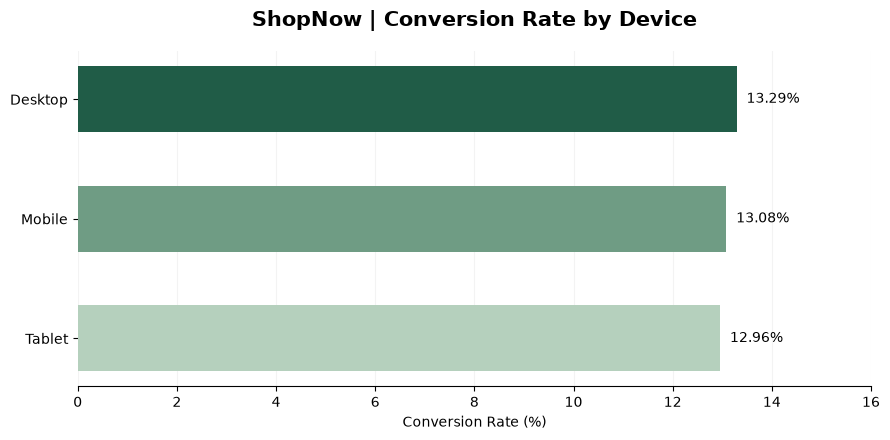

In [23]:

# ShopNow - Visual Insights
# Device Type vs Conversion Rate

import matplotlib.pyplot as plt
import pandas as pd

visual_data = web_sessions.copy()

visual_data["converted"] = pd.to_numeric(
    visual_data["converted"], errors="coerce"
)

visual_data = visual_data[
    visual_data["converted"].isin([0, 1])
].dropna(subset=["device_type"])

rates = (
    visual_data.groupby("device_type")["converted"]
    .mean() * 100
).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 4.5))

colors = ["#205C47", "#6F9C84", "#B5D0BD"]

bars = ax.barh(
    rates.index.str.title(),
    rates.values,
    color=colors[:len(rates)],
    height=0.55
)

ax.invert_yaxis()
ax.set_xlim(0, 16)
ax.set_xlabel("Conversion Rate (%)")
ax.set_title(
    "ShopNow | Conversion Rate by Device",
    fontsize=15, fontweight="bold", pad=18
)

for bar in bars:
    width = bar.get_width()
    ax.text(
        width + 0.2,
        bar.get_y() + bar.get_height()/2,
        f"{width:.2f}%",
        va="center",
        fontsize=10
    )

ax.spines[["top", "right", "left"]].set_visible(False)
ax.grid(axis="x", alpha=0.15)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


### Visual Insight: Device Conversion Performance

The chart shows that conversion rates are almost identical across desktop, mobile, and tablet users.

Although desktop users have a slightly higher conversion rate, the Chi-square test did not find a statistically significant association between device type and conversion.

This suggests that ShopNow should focus on improving the overall customer experience rather than prioritizing one device based only on these conversion rates.

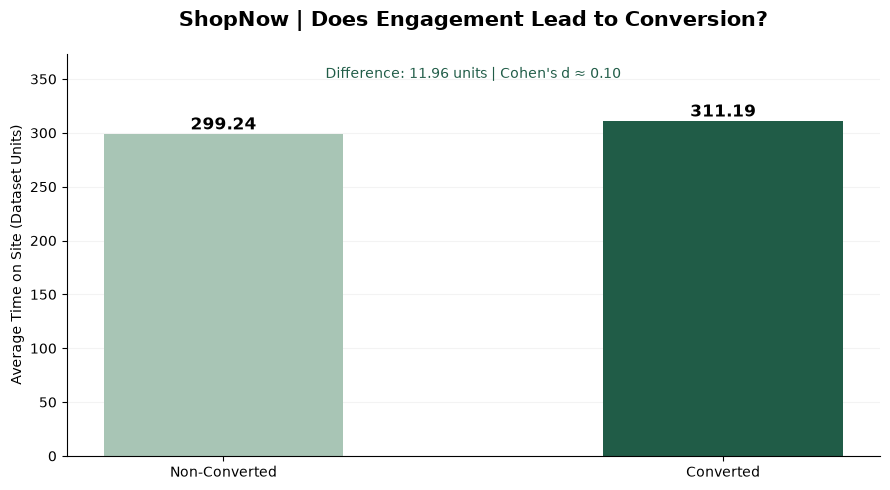

In [24]:

# ShopNow - Visual Insight 2
# Average Time on Site vs Conversion

import matplotlib.pyplot as plt

data = web_sessions.copy()

data["time_on_site"] = pd.to_numeric(
    data["time_on_site"], errors="coerce"
)
data["converted"] = pd.to_numeric(
    data["converted"], errors="coerce"
)

data = data.dropna(subset=["time_on_site", "converted"])
data = data[data["converted"].isin([0, 1])]

average_time = (
    data.groupby("converted")["time_on_site"].mean()
)

labels = ["Non-Converted", "Converted"]
values = [average_time.loc[0], average_time.loc[1]]

fig, ax = plt.subplots(figsize=(9, 5))

colors = ["#A8C5B5", "#205C47"]

bars = ax.bar(
    labels, values,
    color=colors,
    width=0.48
)

for bar in bars:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width()/2,
        height + 4,
        f"{height:.2f}",
        ha="center",
        fontsize=12,
        fontweight="bold"
    )

difference = values[1] - values[0]

ax.set_ylim(0, max(values) * 1.20)
ax.set_ylabel("Average Time on Site (Dataset Units)")

ax.set_title(
    "ShopNow | Does Engagement Lead to Conversion?",
    fontsize=15,
    fontweight="bold",
    pad=20
)

ax.text(
    0.5, 0.94,
    f"Difference: {difference:.2f} units | Cohen's d ≈ 0.10",
    transform=ax.transAxes,
    ha="center",
    color="#205C47",
    fontsize=10
)

ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.15)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


### Visual Insight: Engagement and Conversion

This chart compares the average time spent on the website by converted and non-converted visitors.

Converted visitors spent slightly more time on the website (311.19 compared to 299.24).

Although the difference was statistically significant, the effect size was very small (Cohen's d = 0.10).

**My Takeaway:** I found this particularly interesting because it shows why statistical significance and business importance should be considered separately. More time on the website is associated with conversion in this analysis, but the difference alone is not enough to guide major business decisions.

In [25]:
%pip install notebook nbconvert

  Using cached beautifulsoup4-4.15.0-py3-none-any.whl.metadata (3.8 kB)
  Using cached bleach-6.4.0-py3-none-any.whl.metadata (32 kB)
  Using cached defusedxml-0.7.1-py2.py3-none-any.whl.metadata (32 kB)
  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached jupyterlab_pygments-0.3.0-py3-none-any.whl.metadata (4.4 kB)
  Using cached mistune-3.3.4-py3-none-any.whl.metadata (1.9 kB)
  Using cached nbclient-0.11.0-py3-none-any.whl.metadata (7.3 kB)
  Using cached nbformat-5.11.1-py3-none-any.whl.metadata (3.7 kB)
  Using cached pandocfilters-1.5.1-py2.py3-none-any.whl.metadata (9.0 kB)
  Using cached webencodings-0.6.1-py3-none-any.whl.metadata (3.4 kB)
  Using cached tinycss2-1.5.1-py3-none-any.whl.metadata (3.0 kB)
  Using cached jsonschema-4.26.0-py3-none-any.whl.metadata (7.6 kB)
  Using cached fastjsonschema-2.22.2-py3-none-any.whl.metadata (2.1 kB)
  Using cached attrs-26.1.0-py3-none-any.whl.metadata (8.8 kB)
  Using cached jsonschema_specifications-2025.9.1-


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip
